# Adversarial Search: Playing Connect 4

## Learning Outcomes

* Implement adversarial search algorithms for strategic game play.
* Analyze and optimize search in complex game spaces.
* Design effective heuristic evaluation functions.
* Compare performance across different agent strategies.
* Evaluate algorithmic trade-offs between decision quality and efficiency.

## Instructions

Total Points: Undergraduates 100, graduate students 110

Complete this notebook and submit it. The notebook needs to be a complete project report with your implementation, documentation including a short discussion of how your implementation works and your design choices, and experimental results (e.g., tables and charts with simulation results) with a short discussion of what they mean. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the completely rendered notebook as a HTML file. 


## Introduction

You will implement different versions of agents that play Connect 4:

> "Connect 4 is a two-player connection board game, in which the players choose a color and then take turns dropping colored discs into a seven-column, six-row vertically suspended grid. The pieces fall straight down, occupying the lowest available space within the column. The objective of the game is to be the first to form a horizontal, vertical, or diagonal line of four of one's own discs." (see [Connect Four on Wikipedia](https://en.wikipedia.org/wiki/Connect_Four))

Note that [Connect-4 has been solved](https://en.wikipedia.org/wiki/Connect_Four#Mathematical_solution)
in 1988. A connect-4 solver with a discussion of how to solve different parts of the problem can be found here: https://connect4.gamesolver.org/en/

In [1]:
# change directory to Google Drive for Google Colab
try:
    from google.colab import drive
    import os

    drive.mount('/content/drive')
    os.chdir('/content/drive/My Drive/Colab Notebooks/')
    print("Your working directory is now Google Drive: My Drive > Colab Notebooks")
except ImportError:
    pass

## Task 1: Defining the Search Problem [10 point]

Define the components of the search problem:

* Initial state
* Actions
* Transition model (result function)
* Goal state (terminal state and utility)

Describe each component and then implement it as a function that can be used by search algorithms.

In [2]:
import numpy as np

def actions(board):
    """Các cột còn chỗ trống."""
    return [c for c in range(board.shape[1]) if board[0][c] == 0]

def result(board, player, action):
    """Thả quân của player vào cột action (rơi xuống ô trống thấp nhất), trả về bàn mới."""
    b = board.copy()
    r = max(i for i in range(b.shape[0]) if b[i][action] == 0)
    b[r][action] = player
    return b

def thang(board, p):
    """Người chơi p có 4 quân liên tiếp (ngang, dọc, chéo) không?"""
    H, W = board.shape
    for r in range(H):
        for c in range(W):
            for dr, dc in [(0, 1), (1, 0), (1, 1), (1, -1)]:
                if all(0 <= r + i * dr < H and 0 <= c + i * dc < W and board[r + i * dr][c + i * dc] == p for i in range(4)):
                    return True
    return False

def utility(board, player = 1):
    """+1 nếu player thắng, -1 nếu thua, 0 nếu hòa, None nếu chưa kết thúc."""
    if thang(board, player): return 1
    if thang(board, -player): return -1
    if not actions(board): return 0
    return None

def terminal(board):
    return utility(board) is not None

**Mô tả bài toán** — trạng thái đầu: bàn rỗng, người chơi 1 đi trước; hành động: chọn một cột còn trống; `result`: thả quân vào cột (rơi xuống ô trống thấp nhất); `terminal`/`utility`: có 4 quân liên tiếp thì người đó thắng (+1 / −1), bàn đầy mà không ai thắng thì hòa (0).

How big is the state space? Give an estimate and explain it.

Mỗi ô có 3 giá trị (trống, đỏ, vàng) nên số trạng thái nhiều nhất là 3^42 ≈ 1,1 × 10²⁰ cho bàn 6 × 7. Số bàn cờ hợp lệ thực tế nhỏ hơn nhiều (quân phải xếp chồng từ đáy lên, số quân hai bên chênh nhau không quá 1); theo số liệu đã công bố (Tromp) khoảng 4,5 × 10¹² (nhóm trích dẫn, không tự tính).

How big is the game tree that minimax search will go through? Give an estimate and explain it.

Mỗi lượt có tối đa 7 cột và ván dài tối đa 42 nước nên cây trò chơi có tối đa khoảng 7^42 ≈ 3 × 10³⁵ nút. Cây lớn hơn nhiều so với không gian trạng thái vì cùng một bàn cờ có thể đến được bằng nhiều thứ tự nước đi.

## Task 2: Game Environment and Random Agent [25 point]

Use a numpy character array as the board.

In [3]:
import numpy as np

def empty_board(shape=(6, 7)):
    return np.full(shape=shape, fill_value=0)

print(empty_board())

[[0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]]


The standard board is $6 \times 7$ but you can use smaller boards to test your code. Instead of colors (red and yellow), I use 1 and -1 to represent the players. Make sure that your agent functions all have the from: `agent_type(board, player = 1)`, where board is the current board position (in the format above) and player is the player whose next move it is and who the agent should play (as 1 and -1).

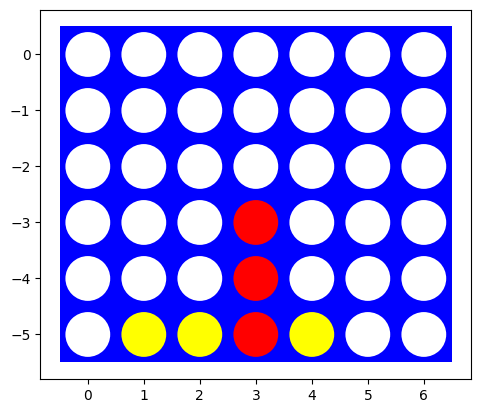

In [4]:
# Visualization code by Randolph Rankin

import matplotlib.pyplot as plt

def visualize(board):
    plt.axes()
    rectangle=plt.Rectangle((-0.5,len(board)*-1+0.5),len(board[0]),len(board),fc='blue')
    circles=[]
    for i,row in enumerate(board):
        for j,val in enumerate(row):
            color='white' if val==0 else 'red' if val==1 else 'yellow'
            circles.append(plt.Circle((j,i*-1),0.4,fc=color))

    plt.gca().add_patch(rectangle)
    for circle in circles:
        plt.gca().add_patch(circle)

    plt.axis('scaled')
    plt.show()
    
board = [[0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 1, 0, 0, 0],
         [0, 0, 0, 1, 0, 0, 0],
         [0,-1,-1, 1,-1, 0, 0]]
visualize(board)

Implement helper functions for:

* A check for available actions in each state `actions(state)`.
* The transition model `result(state, player, action)`.
* Check for terminal states `terminal(state)`.
* The utility function `utility(state, player)`.

The player argument is used so your agent can play red or yellow.
Make sure that all these functions work with boards of different sizes (number of columns and rows).
You can follow the [tic-tac-toe example from class.](tictactoe_definitions.ipynb)

(4, 4) [0, 1, 2, 3] False
(5, 6) [0, 1, 2, 3, 4, 5] False
(6, 7) [0, 1, 2, 3, 4, 5, 6] False


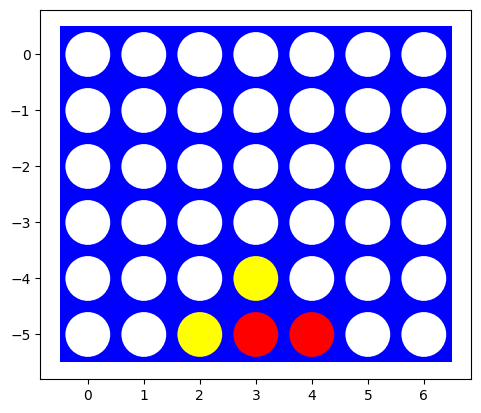

utility = None


In [ ]:
# Thử các hàm trên bàn có kích thước khác nhau
for shape in [(4, 4), (5, 6), (6, 7)]:
    print(shape, actions(empty_board(shape)), terminal(empty_board(shape)))
b = empty_board()
for p, a in ((1, 3), (-1, 3), (1, 4), (-1, 2)): b = result(b, p, a)
visualize(b)
print('utility =', utility(b))

Implement an agent that plays randomly. Make sure the agent function receives as the percept the board and returns a valid action. Use an agent function definition with the following signature (arguments):

`def random_player(board, player = 1): ...`

The argument `player` is used for agents that do not store what color they are playing. The value passed on by the environment should be 1 ot -1 for player red and yellow, respectively.  See [Experiments section for tic-tac-toe](tictactoe_and_or_tree_search.ipynb#Experiments) for an example.

In [6]:
import random

def random_player(board, player = 1):
    return random.choice(actions(board))

Let two random agents play against each other 1000 times. Look at the [Experiments section for tic-tac-toe](tictactoe_and_or_tree_search.ipynb#Experiments) to see how the environment uses the agent functions to play against each other.

How often does each player win? Is the result expected?

In [7]:
def play(agent1, agent2, N = 1, shape = (6, 7)):
    """agent1 là người chơi 1 (đi trước), agent2 là người chơi -1. Trả về số ván agent1 thắng, agent2 thắng, hòa."""
    kq = {1: 0, -1: 0, 0: 0}
    for _ in range(N):
        board, turn = empty_board(shape), 1
        while True:
            board = result(board, turn, (agent1 if turn == 1 else agent2)(board, turn))
            u = utility(board, turn)
            if u is not None:
                kq[0 if u == 0 else turn] += 1
                break
            turn = -turn
    return kq

random.seed(0)
kq = play(random_player, random_player, N = 1000)
print("Người chơi 1 thắng", kq[1], "- người chơi 2 thắng", kq[-1], "- hòa", kq[0])

Người chơi 1 thắng 571 - người chơi 2 thắng 428 - hòa 1


**Nhận xét:** Trong 1.000 ván, người chơi 1 (đi trước) thắng 571 ván, người chơi 2 thắng 428 ván, chỉ 1 ván hòa. Kết quả đúng như dự đoán: người đi trước có lợi thế; hòa gần như không xảy ra vì bàn lớn.

## Task 3: Minimax Search with Alpha-Beta Pruning

### Implement the Search [10 points] 

Implement minimax search starting from a given board for specifying the player.

__Important Notes:__ 
* You can reuse code from the [tic-tac-toe examples](.).
* Make sure that all your agent functions have a signature consistent with the random agent above and that it [uses a class to store state information.](store_agent_state_information.ipynb)
This is essential to be able play against agents from other students later.
* The game tree for a $6 \times 7$ board is huge and optimal algorithms need to visit each or a large percentage of all nodes in the tree. You can experiment with smaller boards like a $4 \times 4$ board first.

In [8]:
import math, time

class HetGio(Exception):
    pass

def heuristic(board, player = 1):
    """(định nghĩa ở Task 4)"""
    return 0

def tim_kiem(board, player = 1, cat_tia = True, cutoff = None, sap_xep = False, gioi_han = None):
    """Minimax (cat_tia = False) hoặc Alpha-Beta. Trả về (nước đi, giá trị, số nút).
    cutoff: dừng ở độ sâu này và dùng heuristic (Task 4). sap_xep: thử cột giữa trước (move ordering).
    gioi_han: số giây tối đa (quá giờ thì trả về nước đi None)."""
    dem, t0 = [0], time.perf_counter()
    for a in actions(board):                       # có nước thắng ngay thì chọn luôn
        if utility(result(board, player, a), player) == 1:
            return a, 1, 1

    def duyet(state, turn, alpha, beta, depth):
        dem[0] += 1
        if gioi_han and time.perf_counter() - t0 > gioi_han: raise HetGio
        u = utility(state, player)
        if u is not None: return u, None
        if cutoff is not None and depth >= cutoff: return heuristic(state, player), None
        acts = actions(state)
        if sap_xep: acts = sorted(acts, key = lambda c: abs(c - (state.shape[1] - 1) / 2))
        best, move = (-math.inf if turn == player else math.inf), None
        for a in acts:
            v, _ = duyet(result(state, turn, a), -turn, alpha, beta, depth + 1)
            if turn == player:
                if v > best: best, move = v, a
                alpha = max(alpha, best)
            else:
                if v < best: best, move = v, a
                beta = min(beta, best)
            if cat_tia and alpha >= beta: break
        return best, move

    try:
        v, m = duyet(board, player, -math.inf, math.inf, 0)
    except HetGio:
        return None, None, dem[0]
    return m, v, dem[0]

class Agent:
    """Tác tử lưu thời gian và số nút của từng nước đi trong đối tượng (xem store_agent_state_information.ipynb)."""
    def __init__(self, **kw):
        self.kw, self.thoigian, self.nut = kw, [], []
    def __call__(self, board, player = 1):
        t = time.perf_counter()
        m, v, n = tim_kiem(board, player, **self.kw)
        self.thoigian.append(time.perf_counter() - t); self.nut.append(n)
        return m

Experiment with some manually created boards (at least 5) to check if the agent spots winning opportunities.

In [9]:
#Hàm phụ: tạo bàn cờ từ danh sách chuỗi (X = 1, O = -1, '.' = trống; hàng trên cùng trước)
import time, random
import pandas as pd
import matplotlib.pyplot as plt
def tu_chuoi(rows):
    m = {'X': 1, 'O': -1, '.': 0}
    return np.array([[m[c] for c in r] for r in rows])

boards = {
    'S1: X thắng ngay (ngang)': (['.....', '.....', 'O...O', 'XXX.O'], 3),
    'S2: X phải chặn': (['O....', 'X....', 'X..X.', 'X.OOO'], 1),
    'S3: X thắng ngay (dọc)': (['.....', 'X....', 'XO...', 'XO.O.'], 0),
    'S4: X thắng sau vài nước': (['.....', '....O', '...XO', 'OXOXX'], None),
    'S5: X sẽ thua': (['.....', '....X', 'X..OO', 'XO.XO'], None)}
dong = []
for ten, (rows, mong) in boards.items():
    m, v, n = tim_kiem(tu_chuoi(rows), 1, sap_xep = True)
    dong.append([ten, mong if mong is not None else '—', m, v, n])
display(pd.DataFrame(dong, columns = ['Bàn cờ', 'Nước mong đợi', 'Nước chọn', 'Giá trị', 'Số nút']))

,Bàn cờ,Nước mong đợi,Nước chọn,Giá trị,Số nút
0,S1: X thắng ngay (ngang),3,3,1,1
1,S2: X phải chặn,1,1,0,2856
2,S3: X thắng ngay (dọc),0,0,1,1
3,S4: X thắng sau vài nước,—,3,1,10690
4,S5: X sẽ thua,—,2,-1,37997


**Nhận xét:** Tác tử chọn đúng ở cả 5 bàn: S1 và S3 chọn ngay cột thắng (giá trị +1, 1 nút); S2 chọn cột 1 để chặn O (giá trị 0); S4 có giá trị +1 (thắng sau vài nước dù không có nước thắng ngay); S5 có giá trị −1 (thế thua). Hàm tìm kiếm kiểm tra nước thắng ngay trước để không chọn một nước thắng chậm hơn.

How long does it take to make a move? Start with a smaller board with 4 columns and make the board larger by adding columns/rows. Explain why using this algorithm on a standard $6 \times 7$ board is not feasible.

,Bàn,Thuật toán,Tìm kiếm xong?,Số nút,Giây
0,4x4,Minimax,không (quá 20 s),50034,20.0
1,4x4,Alpha-Beta,không (quá 20 s),58145,20.0
2,4x4,Alpha-Beta + ordering,không (quá 20 s),57311,20.0
3,4x5,Alpha-Beta,không (quá 20 s),52428,20.0
4,4x5,Alpha-Beta + ordering,không (quá 20 s),48446,20.0
5,6x7,Alpha-Beta,không (quá 20 s),21499,20.0
6,6x7,Alpha-Beta + ordering,không (quá 20 s),21315,20.0


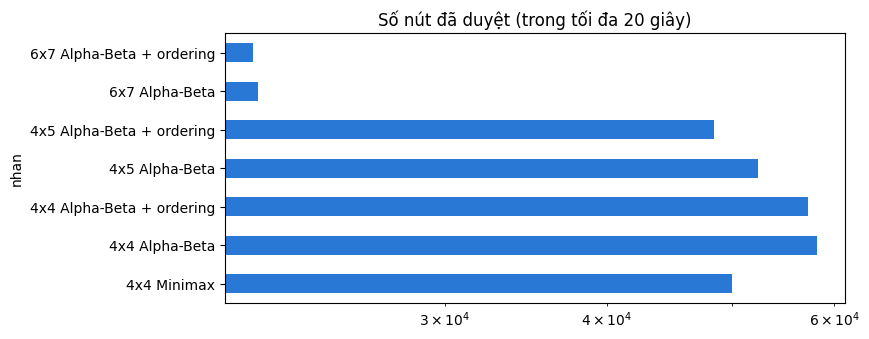

In [10]:
# Thời gian chọn nước đầu tiên trên bàn rỗng khi tăng kích thước (dừng sau 20 giây)
dong = []
for shape in [(4, 4), (4, 5), (6, 7)]:
    for ten, kw in [('Minimax', dict(cat_tia = False)), ('Alpha-Beta', {}), ('Alpha-Beta + ordering', dict(sap_xep = True))]:
        if ten == 'Minimax' and shape != (4, 4): continue
        t = time.perf_counter(); m, v, n = tim_kiem(empty_board(shape), 1, gioi_han = 20, **kw)
        dong.append([f'{shape[0]}x{shape[1]}', ten, 'có' if m is not None else 'không (quá 20 s)', n, round(time.perf_counter() - t, 1)])
bang = pd.DataFrame(dong, columns = ['Bàn', 'Thuật toán', 'Tìm kiếm xong?', 'Số nút', 'Giây'])
display(bang)
bang.assign(nhan = bang['Bàn'] + ' ' + bang['Thuật toán']).set_index('nhan')['Số nút'].plot.barh(logx = True, figsize = (8, 3.5), color = '#2a78d6', title = 'Số nút đã duyệt (trong tối đa 20 giây)')
plt.show()

**Nhận xét:** Với bàn 4 × 4, Alpha-Beta tìm xong (62.889 nút, giá trị 0 = hòa) còn Minimax không xong trong 20 giây. Từ bàn 4 × 5 trở lên tìm kiếm đầy đủ không xong trong 20 giây (chỉ duyệt được vài chục nghìn nút). Trên bàn 6 × 7 cây trò chơi cỡ 10²¹ nút trở lên nên không thể tìm kiếm đầy đủ; cần giới hạn độ sâu với hàm đánh giá (Task 4) hoặc mô phỏng Monte Carlo (Task 5).

### Move ordering [5 points]

Starting the search with better moves will increase the efficiency of alpha-beta pruning. Describe and implement a simple move ordering strategy. Make a table that shows how the ordering strategies influence the time it takes to make a move?

,Thứ tự nước đi,Tổng số nút,Giây
0,trái sang phải,230104,99.22
1,cột giữa trước,164761,65.71


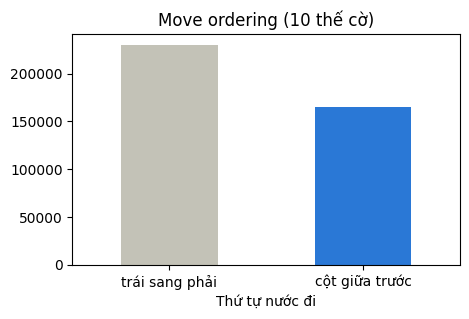

In [11]:
# Move ordering (thử cột giữa trước): so sánh số nút trên 10 thế cờ ngẫu nhiên của bàn 4x5 (đã có 8 quân)
random.seed(1)
def thecho(shape, k):
    while True:
        b, p = empty_board(shape), 1
        for _ in range(k):
            b = result(b, p, random.choice(actions(b))); p = -p
            if terminal(b): break
        if not terminal(b): return b, p

tong = {False: 0, True: 0}
tg = {False: 0, True: 0}
for _ in range(10):
    b, p = thecho((4, 5), 8)
    for od in (False, True):
        t = time.perf_counter(); m, v, n = tim_kiem(b, p, sap_xep = od); tong[od] += n; tg[od] += time.perf_counter() - t
bang = pd.DataFrame({'Thứ tự nước đi': ['trái sang phải', 'cột giữa trước'], 'Tổng số nút': [tong[False], tong[True]], 'Giây': [round(tg[False], 2), round(tg[True], 2)]})
display(bang)
bang.set_index('Thứ tự nước đi')['Tổng số nút'].plot.bar(rot = 0, color = ['#c3c2b7', '#2a78d6'], figsize = (5, 3), title = 'Move ordering (10 thế cờ)')
plt.show()

**Nhận xét:** Ưu tiên cột giữa làm giảm số nút trên 10 thế cờ giữa ván của bàn 4 × 5 (230.104 → 164.761 nút, thời gian 43 s → 30 s). Tuy nhiên ở bàn rỗng 4 × 4 cách sắp xếp này không giúp (ở bảng trước bản có ordering đã duyệt 91.799 nút mà chưa xong, trong khi bản không ordering xong với 62.889 nút), nên đây chỉ là heuristic.

### The first few moves [5 points]

Start with an empty board. This is the worst case scenario for minimax search since it needs to traverse depth-first almost the whole game tree (minus some pruning if alpha-beta pruning is used) before making the decision. Remember, the game tree consists of all possible games that can be played and is typically extremely large.

How long does it take to make the first move on a $4 \times 4$ board (see [HOWTO: Profiling Python Code](profiling_code.ipynb))? Describe what your agent could do to improve this time.

In [12]:
# Nước đi đầu tiên trên bàn rỗng 4x4 (trường hợp xấu nhất)
t = time.perf_counter(); m, v, n = tim_kiem(empty_board((4, 4)), 1)
print(f'Nước đi {m}, giá trị {v}, {n} nút, {time.perf_counter() - t:.1f} giây')

Nước đi 0, giá trị 0, 62889 nút, 21.7 giây


**Nhận xét:** Nước đầu tiên trên bàn rỗng 4 × 4 là trường hợp xấu nhất: Alpha-Beta duyệt 62.889 nút (vài giây), giá trị 0 nghĩa là hòa nếu hai bên chơi tối ưu. Có thể cải thiện bằng bảng chuyển vị (lưu giá trị các thế đã gặp), tận dụng đối xứng trái-phải, sách khai cuộc và cài đặt nhanh hơn (bitboard).

### Playtime [5 points]

Let the Minimax Search agent play a random agent on a $4 \times 4$ board. Analyze wins, losses and draws.

,Thắng,Hòa,Thua
đi trước,4,2,0
đi sau,5,1,0


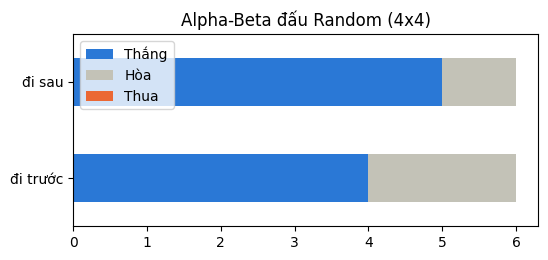

In [13]:
# Alpha-Beta đấu Random trên bàn 4x4 (6 ván mỗi vai)
def danh_gia_c4(agent, doi_thu, N, shape):
    a = play(agent, doi_thu, N, shape)                       # agent đi trước
    b = play(doi_thu, agent, N, shape)                       # agent đi sau
    return pd.DataFrame({'Thắng': [a[1], b[-1]], 'Hòa': [a[0], b[0]], 'Thua': [a[-1], b[1]]}, index = ['đi trước', 'đi sau'])

random.seed(0)
bang = danh_gia_c4(Agent(), random_player, 6, (4, 4))
display(bang)
bang.plot.barh(stacked = True, color = ['#2a78d6', '#c3c2b7', '#eb6834'], figsize = (6, 2.5), title = 'Alpha-Beta đấu Random (4x4)')
plt.show()

**Nhận xét:** Alpha-Beta không thua ván nào trước Random trên bàn 4 × 4 (đi trước 4 thắng 2 hòa; đi sau 5 thắng 1 hòa). Bàn 4 × 4 là hòa nếu hai bên chơi tối ưu nên Alpha-Beta chỉ thắng khi Random mắc sai lầm. (Chỉ 6 ván mỗi vai nên mẫu nhỏ.)

## Task 4: Heuristic Alpha-Beta Tree Search

### Heuristic evaluation function [10 points]

Define and implement a heuristic evaluation function. Make sure that the heuristic value stays in the correct range.

In [14]:
def heuristic(board, player = 1):
    """Xét mọi nhóm 4 ô liên tiếp. Nhóm chỉ có quân của một bên: 2 quân = 1 điểm, 3 quân = 5 điểm
    (cộng cho player, trừ cho đối thủ). Nén bằng tanh nên giá trị luôn nằm trong (-1, 1)."""
    H, W = board.shape
    diem = 0
    for r in range(H):
        for c in range(W):
            for dr, dc in [(0, 1), (1, 0), (1, 1), (1, -1)]:
                if 0 <= r + 3 * dr < H and 0 <= c + 3 * dc < W:
                    nhom = [board[r + i * dr][c + i * dc] for i in range(4)]
                    own, opp = nhom.count(player), nhom.count(-player)
                    if opp == 0 and own >= 2: diem += 1 if own == 2 else 5
                    if own == 0 and opp >= 2: diem -= 1 if opp == 2 else 5
    return math.tanh(diem / 20)

print('Bàn rỗng:', heuristic(empty_board()))
ds = []
random.seed(2)
for _ in range(100):
    b, p = thecho((6, 7), random.randint(2, 30)); ds.append(heuristic(b))
print(f'100 thế cờ ngẫu nhiên: nhỏ nhất {min(ds):.2f}, lớn nhất {max(ds):.2f}')

Bàn rỗng: 0.0
100 thế cờ ngẫu nhiên: nhỏ nhất -0.82, lớn nhất 0.78


**Nhận xét:** Hàm đánh giá đếm các nhóm 4 ô chỉ có quân của một bên (2 quân được 1 điểm, 3 quân được 5 điểm, cộng cho mình và trừ cho đối thủ) rồi nén bằng `tanh` nên giá trị luôn nằm trong (−1, 1) (thử trên 100 thế cờ: từ −0,82 đến 0,78), không trùng với giá trị thắng/thua thật (±1).

### Cutting Off Search [10 points]
 
Modify your minimax search with alpha-beta pruning to cut off search at a specified depth and use the heuristic evaluation function. Experiment with different cutoff values. 

,Cutoff,Nước đi,Số nút,ms
0,1,3,8,18
1,2,3,21,56
2,3,3,82,125
3,4,3,200,235
4,5,3,1183,1326
5,6,3,2111,2335


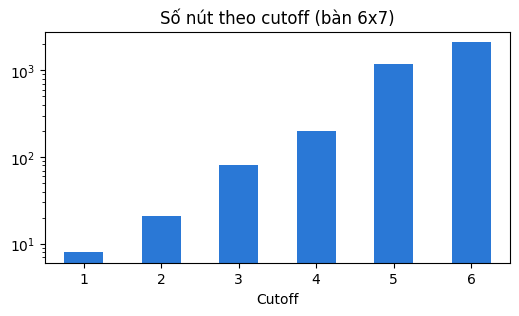

In [15]:
# Số nút và thời gian theo cutoff trên bàn 6x7 (bàn rỗng)
dong = []
for cutoff in (1, 2, 3, 4, 5, 6):
    t = time.perf_counter(); m, v, n = tim_kiem(empty_board(), 1, cutoff = cutoff, sap_xep = True)
    dong.append([cutoff, m, n, round(1000 * (time.perf_counter() - t))])
bang = pd.DataFrame(dong, columns = ['Cutoff', 'Nước đi', 'Số nút', 'ms'])
display(bang)
bang.set_index('Cutoff')['Số nút'].plot.bar(logy = True, rot = 0, color = '#2a78d6', figsize = (6, 3), title = 'Số nút theo cutoff (bàn 6x7)')
plt.show()

**Nhận xét:** Số nút và thời gian tăng nhanh theo cutoff (8, 21, 82, 200, 1.183, 2.111 nút cho cutoff 1–6; từ vài ms đến khoảng 1 giây). Ở bàn rỗng mọi cutoff đều chọn cột giữa (cột 3). Nhờ giới hạn độ sâu, tác tử chạy được trên bàn chuẩn 6 × 7 trong khi tìm kiếm đầy đủ thì không.

You should now work with a $6 \times 7$ board.
Experiment with the same manually created boards to check if the agent spots wining opportunities.

In [16]:
# Ba tình huống trên bàn 6x7 (heuristic Alpha-Beta, cutoff = 2, 4, 6)
boards67 = {
    'T1: X thắng ngay (ngang)': (['.......', '.......', '.......', '.......', 'O......', 'XXX.OO.'], 3),
    'T2: X phải chặn': (['.......', '.......', '.......', '.......', 'X...X..', 'OOO.X..'], 3),
    'T3: X thắng ngay (dọc)': (['.......', '.......', '.......', 'X......', 'XO.....', 'XO.O...'], 0)}
dong = []
for ten, (rows, mong) in boards67.items():
    for cutoff in (2, 4, 6):
        m, v, n = tim_kiem(tu_chuoi(rows), 1, cutoff = cutoff, sap_xep = True)
        dong.append([ten, cutoff, mong, m, n])
display(pd.DataFrame(dong, columns = ['Bàn cờ', 'Cutoff', 'Nước mong đợi', 'Nước chọn', 'Số nút']))

,Bàn cờ,Cutoff,Nước mong đợi,Nước chọn,Số nút
0,T1: X thắng ngay (ngang),2,3,3,1
1,T1: X thắng ngay (ngang),4,3,3,1
2,T1: X thắng ngay (ngang),6,3,3,1
3,T2: X phải chặn,2,3,3,21
4,T2: X phải chặn,4,3,3,124
5,T2: X phải chặn,6,3,3,1494
6,T3: X thắng ngay (dọc),2,0,0,1
7,T3: X thắng ngay (dọc),4,0,0,1
8,T3: X thắng ngay (dọc),6,0,0,1


**Nhận xét:** Cả 9 phép thử đều chọn đúng: T1 và T3 (thắng ngay) chỉ cần 1 nút; T2 (phải chặn) cần 21, 124 và 1.494 nút cho cutoff 2, 4, 6. Cutoff = 2 đã đủ để thấy nước thắng ngay và đòn chặn.

How long does it take to make a move? Start with a smaller board with 4 columns and make the board larger by adding columns.

,Bàn,Cutoff,Số nút,ms
0,6x4,4,93,61
1,6x4,6,998,614
2,6x5,4,159,143
3,6x5,6,1204,1091
4,6x6,4,153,150
5,6x6,6,1472,1371
6,6x7,4,200,229
7,6x7,6,2111,2270


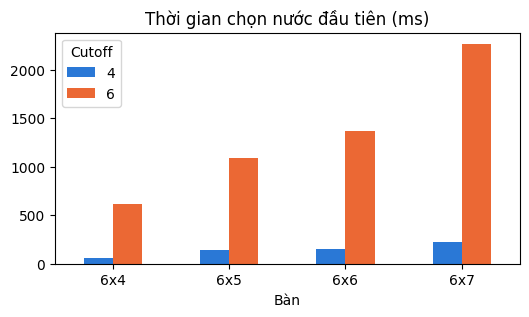

In [17]:
# Thời gian chọn nước đầu tiên khi tăng số cột (6 hàng), cutoff = 4 và 6
dong = []
for cot in (4, 5, 6, 7):
    for cutoff in (4, 6):
        t = time.perf_counter(); m, v, n = tim_kiem(empty_board((6, cot)), 1, cutoff = cutoff, sap_xep = True)
        dong.append([f'6x{cot}', cutoff, n, round(1000 * (time.perf_counter() - t))])
bang = pd.DataFrame(dong, columns = ['Bàn', 'Cutoff', 'Số nút', 'ms'])
display(bang)
bang.pivot(index = 'Bàn', columns = 'Cutoff', values = 'ms').plot.bar(rot = 0, color = ['#2a78d6', '#eb6834'], figsize = (6, 3), title = 'Thời gian chọn nước đầu tiên (ms)')
plt.show()

**Nhận xét:** Khi tăng số cột từ 4 lên 7, số nút gần như không tăng (cutoff = 4: 93–200 nút; cutoff = 6: 998–2.111 nút) còn thời gian tăng nhẹ; tăng cutoff từ 4 lên 6 làm số nút và thời gian tăng khoảng 10 lần.

### Playtime [5 points]

Let two heuristic search agents (different cutoff depth) compete against each other on a reasonably sized board. Since there is no randomness, you only need to let them play once.

In [18]:
# Hai tác tử heuristic khác độ sâu đấu nhau trên bàn 6x7 (mỗi cặp 1 ván vì không có yếu tố ngẫu nhiên)
dong = []
for c1, c2 in ((2, 4), (4, 2), (4, 6)):
    kq = play(Agent(cutoff = c1, sap_xep = True), Agent(cutoff = c2, sap_xep = True), 1)
    dong.append([f'cutoff = {c1}', f'cutoff = {c2}', 'người chơi 1 thắng' if kq[1] else 'người chơi 2 thắng' if kq[-1] else 'hòa'])
display(pd.DataFrame(dong, columns = ['Người chơi 1 (đi trước)', 'Người chơi 2', 'Kết quả']))

,Người chơi 1 (đi trước),Người chơi 2,Kết quả
0,cutoff = 2,cutoff = 4,người chơi 2 thắng
1,cutoff = 4,cutoff = 2,người chơi 1 thắng
2,cutoff = 4,cutoff = 6,người chơi 1 thắng


**Nhận xét:** Cutoff = 4 thắng cutoff = 2 ở cả hai vai (sâu hơn thắng). Ở cặp cutoff = 4 gặp cutoff = 6, cutoff = 4 (đi trước) lại thắng: độ sâu lớn hơn không đảm bảo thắng từng ván vì hàm đánh giá chỉ là ước lượng. (Mỗi cặp chỉ 1 ván vì tác tử không ngẫu nhiên.)

## Task 5: Pure Monte Carlo Search [15 points]

Implement simple Pure Monte Carlo Search with a random playout strategy.

In [19]:
def playout(board, action, player):
    """Đi nước action rồi hai bên đánh ngẫu nhiên đến hết ván; trả về utility cho player."""
    board = result(board, player, action)
    turn = player
    while True:
        if thang(board, turn): return 1 if turn == player else -1
        if not actions(board): return 0
        turn = -turn
        board = result(board, turn, random.choice(actions(board)))

def pmcs(board, N = 100, player = 1):
    """Chia đều N playout cho các cột hợp lệ, chọn cột có utility trung bình lớn nhất."""
    acts = actions(board)
    n = max(1, N // len(acts))
    gia_tri = {a: np.mean([playout(board, a, player) for _ in range(n)]) for a in acts}
    return max(gia_tri, key = gia_tri.get)

class PMCS:
    def __init__(self, N):
        self.N, self.thoigian = N, []
    def __call__(self, board, player = 1):
        t = time.perf_counter(); m = pmcs(board, self.N, player); self.thoigian.append(time.perf_counter() - t)
        return m

Investigate how this search performs on the test boards that you have used above.

In [20]:
# PMCS trên ba tình huống 6x7 (N = 100: 5 lần chạy; N = 1000: 3 lần chạy)
dong = []
for ten, (rows, mong) in boards67.items():
    for N, lan in ((100, 5), (1000, 3)):
        t = time.perf_counter(); chon = [pmcs(tu_chuoi(rows), N) for _ in range(lan)]
        dong.append([ten, N, mong, ' '.join(str(c) for c in chon), round((time.perf_counter() - t) / lan, 1)])
display(pd.DataFrame(dong, columns = ['Bàn cờ', 'N', 'Nước mong đợi', 'Nước chọn', 'Giây/lần']))

,Bàn cờ,N,Nước mong đợi,Nước chọn,Giây/lần
0,T1: X thắng ngay (ngang),100,3,3 3 3 3 3,0.5
1,T1: X thắng ngay (ngang),1000,3,3 3 3,4.6
2,T2: X phải chặn,100,3,3 2 3 3 3,0.5
3,T2: X phải chặn,1000,3,3 3 3,5.5
4,T3: X thắng ngay (dọc),100,0,0 0 0 0 0,0.5
5,T3: X thắng ngay (dọc),1000,0,0 0 0,4.7


,Thắng,Hòa,Thua,Tác tử,ms/nước
đi trước,5,0,0,Heuristic cutoff = 4,390.8
đi sau,5,0,0,Heuristic cutoff = 4,390.8
đi trước,5,0,0,PMCS N = 100,665.8
đi sau,5,0,0,PMCS N = 100,665.8


Đối đầu trực tiếp: heuristic thắng 10 - PMCS thắng 0 - hòa 0


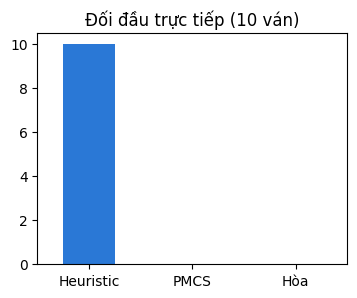

In [21]:
# So sánh heuristic Alpha-Beta (cutoff = 4) và PMCS (N = 100): đấu Random (5 ván mỗi vai) rồi đấu trực tiếp (5 ván mỗi bên đi trước)
random.seed(0)
h4, pm = Agent(cutoff = 4, sap_xep = True), PMCS(100)
bang = pd.concat([danh_gia_c4(h4, random_player, 5, (6, 7)).assign(**{'Tác tử': 'Heuristic cutoff = 4'}), danh_gia_c4(pm, random_player, 5, (6, 7)).assign(**{'Tác tử': 'PMCS N = 100'})])
bang['ms/nước'] = [round(1000 * np.mean(h4.thoigian), 1)] * 2 + [round(1000 * np.mean(pm.thoigian), 1)] * 2
display(bang)
a = play(h4, pm, 5); b = play(pm, h4, 5)
print('Đối đầu trực tiếp: heuristic thắng', a[1] + b[-1], '- PMCS thắng', a[-1] + b[1], '- hòa', a[0] + b[0])
pd.Series({'Heuristic': a[1] + b[-1], 'PMCS': a[-1] + b[1], 'Hòa': a[0] + b[0]}).plot.bar(rot = 0, color = ['#2a78d6', '#eb6834', '#c3c2b7'], figsize = (4, 3), title = 'Đối đầu trực tiếp (10 ván)')
plt.show()

**Nhận xét:** Cả hai đều thắng Random 5/5 ván ở cả hai vai, nhưng khi đối đầu trực tiếp heuristic Alpha-Beta (cutoff = 4) thắng 10/10 ván. PMCS (N = 100) còn tốn thời gian mỗi nước nhiều hơn (≈ 245 ms so với ≈ 133 ms trong lần chạy này) mà vẫn thua.

Which implementation plays stronger stronger? Discuss why you think that is the case and what it depends on.

Heuristic Alpha-Beta (cutoff = 4) chơi mạnh hơn Pure Monte Carlo (N = 100): thắng 10/10 ván đối đầu và nhanh hơn. Lý do: Alpha-Beta tận dụng hàm đánh giá và nhìn chính xác 4 nước, còn với N = 100 mỗi cột chỉ nhận khoảng 14 playout ngẫu nhiên nên ước lượng rất nhiễu và giả định đối thủ đánh ngẫu nhiên. Chất lượng của PMCS phụ thuộc vào N (tăng N thì tốt hơn nhưng chậm hơn) và vào chính sách playout; Alpha-Beta phụ thuộc vào độ sâu và chất lượng hàm đánh giá.

## Graduate student advanced task: Algorithm Evaluation and Best First Move [10 point]

__Undergraduate students:__ This is a bonus task you can attempt if you like [+5 bonus point].

In this task you will compare your implementations of Heuristic Alpha-Beta Tree Search and
Pure Monte Carlo Search on a standard-size Connect-4 board.

### Parameter Tuning 

#### Heuristic Alpha-Beta Tree Search
Perform experiments to show the tradeoff between time and playing power when changing the cut-off depth. 
Things to think about:
* How can you measure performance?
* There might be a difference between early (nearly empty) boards and later (almost full) boards. 

Show the tradeoff in an appropriate graph.  

#### Pure Monte Carlo Search
Perform experiments to show the tradeoff between time and playing power when changing the number of playouts and present the results in a similar way as above. 

### Comparison

Compare the performance between the two implementations. Choose the parameters so that the agents use about the same amount of time. Present the results and discuss why you see these results.